# COMP3602 · Week 4 Lab — Investigating Student Learning Data
**From messy records to reliable insights** · 90 minutes · Beginner–intermediate

**Scenario:** The university wants to examine student learning habits, exam performance, and attendance. You have two CSV files that contain deliberate data-quality problems. Investigate before changing anything.

**Files:** `student_learning.csv`, `student_attendance.csv` (place in the same folder as this notebook).

**Objectives:** Identify and justify cleaning decisions; detect outliers using IQR and Z-score; inspect noisy numerical data visually; merge two sources; use Week 3 frequency distributions and charts; use Week 2 simple random sampling.

**Important:** An unusual value is not automatically wrong. Write short explanations alongside your code. Use simple Pandas and Matplotlib commands.

**Data dictionary**

| Column | Meaning / expected range |
|---|---|
| Student_ID | Student identifier; one record per student expected |
| Age | Years; normally 18–25 |
| Program | CS, AI, IT, DS (equivalent full names may appear) |
| City | Muscat, Seeb, Sohar, Nizwa |
| Study_Hours | Average **daily** study hours; most students expected near 1–10 |
| Screen_Time | Average daily **recreational** screen hours; measurements can naturally vary |
| Exam_Score | Exam mark, 0–100 |
| StudentNo | Student identifier in the attendance file |
| Attendance | Attendance percentage, 0–100 |

**Guidance:** Complete the code cells and answer the written questions. The tasks deliberately mix topics rather than following lecture order.

## Setup — Load both CSV files

In [13]:
# === Write your answer here: ===
import pandas as pd 
import matplotlib.pyplot as plt

df = pd.read_csv('student_attendance.csv') 
dff = pd.read_csv('student_learning.csv') 



## Investigation 1 — Count students in each academic program
1. Check the number of rows, missing values, and duplicate rows. 2. Display the raw frequency of each `Program` category and draw a bar chart. 3. Explain why the first bar chart may be misleading and what must be standardized.

**Hint:** `shape`, `isnull().sum()`, `duplicated().sum()`, `value_counts()`, `plot(kind="bar")`.

**Explain:** Do differently written labels necessarily represent different programs?

(80, 2)
StudentNo     0
Attendance    0
dtype: int64
0

 Program
CS                         21
DS                         21
IT                         20
AI                         12
cs                          1
Computer Science            1
ai                          1
Artificial Intelligence     1
it                          1
Information Technology      1
ds                          1
Data Science                1
Name: count, dtype: int64


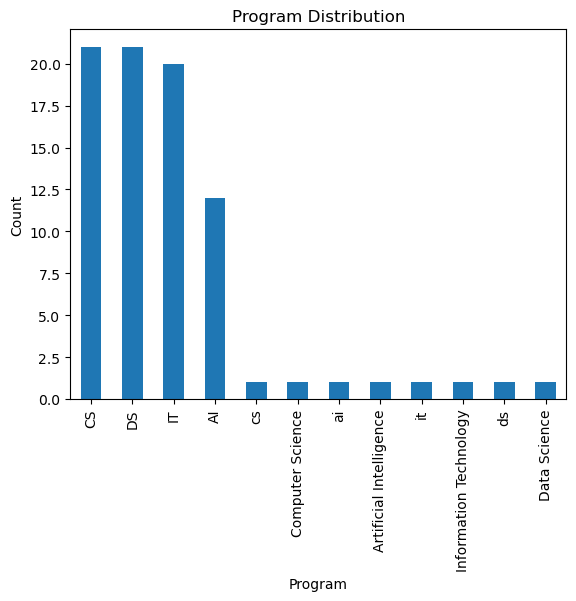

In [3]:
# === Write your answer here: ===
#1-
print(df.shape)
print(df.isnull().sum())
print(df.duplicated().sum())

#2-
prog = dff["Program"].value_counts()
print("\n", prog)
prog.plot(kind='bar', title='Program Distribution')
plt.xlabel("Program")
plt.ylabel('Count')
plt.show()




## Investigation 2 — Identify unusual daily study-hour values
1. Draw a box plot of `Study_Hours`. 2. Calculate Q1, Q3, IQR, and the lower/upper fences. 3. Display records flagged by IQR. 4. Calculate Z-scores using the **population standard deviation** (`ddof=0`), and display records with `|z| > 3`. 5. Compare the two methods. **Do not delete flagged rows.**

**Hint:** Use `quantile(0.25)`, `quantile(0.75)`, `mean()`, `std(ddof=0)`, and Boolean filtering. Work on the original data before making corrections.

**Explain:** Are IQR and Z-score guaranteed to flag identical records? Why not?

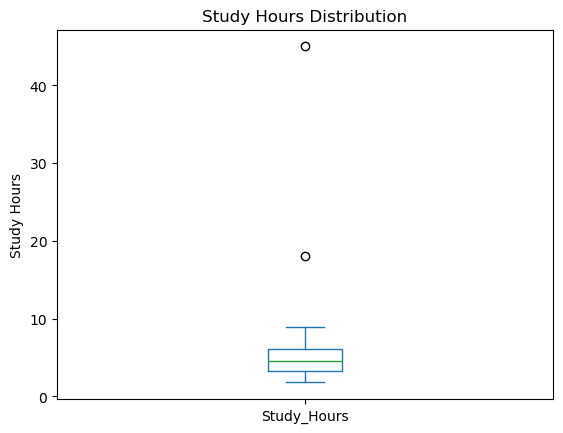

Q1: 3.3
Q3: 6.1
IQR: 2.8
Lower Bound: -0.8999999999999995
Upper Bound: 10.299999999999999

   Student_ID   Age Program   City  Study_Hours  Screen_Time  Exam_Score
39       S140  19.0      DS  Sohar         45.0          7.0        54.0
73       S173  25.0      CS  Sohar         18.0          6.3        42.0

   Student_ID   Age Program   City  Study_Hours  Screen_Time  Exam_Score
39       S140  19.0      DS  Sohar         45.0          7.0        54.0

IQR Flagged: 39    S140
73    S173
Name: Student_ID, dtype: object
Z-Score Flagged: 39    S140
Name: Student_ID, dtype: object


In [10]:
# === Write your answer here: ===
#1-
dff["Study_Hours"].plot(kind='box',  title='Study Hours Distribution')
plt.ylabel('Study Hours')
plt.show()

#2-
Q1 = dff["Study_Hours"].quantile(0.25)
Q3 = dff["Study_Hours"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print()

#3-
iqr_out = dff[(dff["Study_Hours"] < lower) | (dff["Study_Hours"] > upper)]
print(iqr_out)
print()

#4-
mean = dff["Study_Hours"].mean()
std = dff["Study_Hours"].std(ddof=0)
zscores = (dff["Study_Hours"] - mean) / std
z_out = dff[zscores.abs() > 3]
print(z_out)
print()


#5-
print("IQR Flagged:",iqr_out['Student_ID'])
print("Z-Score Flagged:",z_out['Student_ID'])

#The IQR method flags both S140  and S173 , but the Z-score method flags only S140. This indicates that S140 is a more extreme outlier compared to the rest of the data, while S173 is less extreme and may not be considered an outlier by the Z-score method.

### Verification note — provided by the university data team
The record for **S140** contains a confirmed typing error: `Study_Hours = 45.0` should be **4.5**. The unusually high study-hours value for **S173** has **not** been verified and must **not** be automatically replaced or deleted. Keep it in the data and document the concern.

**Decision:** Correct only the verified error. Keep the unverified value and consider its effect when interpreting charts.

## Investigation 3 — Produce a consistent student dataset
1. Remove exact duplicate rows. 2. Correct the **verified** study-hours error using `Student_ID`. 3. Replace missing ages with the median; replace missing cities with `Unknown`; for this exercise, exclude records with missing `Exam_Score` from subsequent exam-score analysis. 4. Standardize program and city labels. 5. Verify missing counts, duplicate counts, and program frequencies.

**Hint:** Use `drop_duplicates()`, `loc[]`, `fillna()`, `dropna(subset=...)`, `replace()`, and `str.title()`. Do not change S173.

**Explain:** Which cleaning steps change the number of records, and which only change values?

In [24]:
# === Write your answer here: ===
#1-
rem_cle = dff.drop_duplicates()
print(rem_cle.shape)
print()

#2-
rem_cle.loc[rem_cle['Student_ID'] == 'S140', 'Study_Hours'] = 4.5
print(dff.shape)
print()


#3-
rem_cle["Age"] = rem_cle["Age"].fillna(rem_cle["Age"].mean())  
rem_cle["City"] = rem_cle["City"].fillna("Unknown")
rem_cle = rem_cle.dropna(subset=['Exam_Score'])
print(rem_cle.shape)
print()


#4-
rem_cle["Program"] = rem_cle["Program"].replace({
    "cs": "CS",
    "it": "IT",
    "ai": "AI",
    "ds": "DS",
    "Data Science": "DS",
    "Information Technology": "IT",
    "Computer Science": "CS",
    "Artificial Intelligence": "AI",
})
rem_cle["City"] = rem_cle["City"].str.title()


#5-
print(rem_cle.isnull().sum())
print()
print(rem_cle.duplicated().sum())
print()
print(rem_cle['Program'].value_counts())
print()
print(rem_cle['City'].value_counts())
print()
print(rem_cle[rem_cle['Student_ID'].isin(['S140', 'S173'])])


(80, 7)

(82, 7)

(78, 7)

Student_ID     0
Age            0
Program        0
City           0
Study_Hours    0
Screen_Time    0
Exam_Score     0
dtype: int64

0

Program
CS    22
IT    22
DS    20
AI    14
Name: count, dtype: int64

City
Sohar      22
Muscat     21
Nizwa      17
Seeb       16
Unknown     2
Name: count, dtype: int64

   Student_ID   Age Program   City  Study_Hours  Screen_Time  Exam_Score
39       S140  19.0      DS  Sohar          4.5          7.0        54.0
73       S173  25.0      CS  Sohar         18.0          6.3        42.0


C:\Users\albra\AppData\Local\Temp\ipykernel_28472\1176458782.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rem_cle["Age"] = rem_cle["Age"].fillna(rem_cle["Age"].mean())
C:\Users\albra\AppData\Local\Temp\ipykernel_28472\1176458782.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rem_cle["City"] = rem_cle["City"].fillna("Unknown")


## Investigation 4 — Combine attendance with the cleaned records
1. Inspect `student_attendance.csv`. 2. Rename `StudentNo` to `Student_ID`. 3. Merge it with the cleaned student data on that identifier, using an **inner** join. 4. Check the row count and missing values after merging.

**Hint:** Use `rename(columns={...})`, `pd.merge(..., on="Student_ID", how="inner")`.

**Explain:** Why is checking the row count after a merge important?

In [30]:
# === Write your answer here: ===
#1-
print(df.shape)
print(df.isnull().sum())
print(df.duplicated().sum())
print(df.head())
print(df.describe())


#2-
df = df.rename(columns={"StudentNo" : "Student_ID"})

#3-
merg = pd.merge(rem_cle, df, on="Student_ID", how="inner")


#4-
print(rem_cle.shape)
print(df.shape)
print(merg.shape)
print(merg.isnull().sum())





(80, 2)
Student_ID    0
Attendance    0
dtype: int64
0
  Student_ID  Attendance
0       S101          65
1       S102          71
2       S103          73
3       S104          72
4       S105          73
       Attendance
count   80.000000
mean    80.925000
std     11.066857
min     62.000000
25%     71.750000
50%     78.500000
75%     90.500000
max     99.000000
(78, 7)
(80, 2)
(78, 8)
Student_ID     0
Age            0
Program        0
City           0
Study_Hours    0
Screen_Time    0
Exam_Score     0
Attendance     0
dtype: int64


## Investigation 5 — Summarize the distribution of exam scores
1. Create a grouped frequency table with intervals **[0, 40), [40, 50), …, [90, 101)**. 2. Add a cumulative-frequency column. 3. Draw a histogram using the same bin boundaries. 4. Interpret which score range has the highest frequency. **Optional:** draw an ogive using cumulative frequencies.

**Hint:** Use `pd.cut()`, `value_counts(sort=False)`, `cumsum()`, and `plot(kind="hist", bins=...)`. The final upper boundary is 101 to include a score of 100.

**Explain:** What does cumulative frequency tell us that ordinary frequency does not?

            frequency  cumulative frequancy
Exam_Score                                 
[0,40)              1                     1
[40,50)             3                     4
[50,60)            27                    31
[60,70)            20                    51
[70,80)            18                    69
[80,90)             8                    77
[90,101)            1                    78


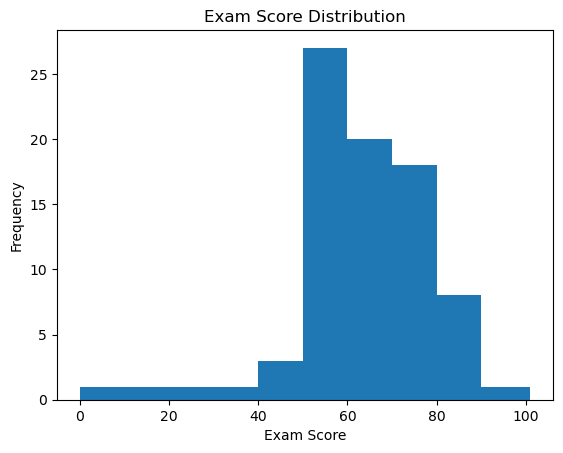

Highest freq interval: [50,60)


In [33]:
# === Write your answer here: ===
#1-
intervals = [0, 40, 50, 60, 70, 80, 90, 101]
labels = ['[0,40)', '[40,50)', '[50,60)', '[60,70)', '[70,80)', '[80,90)', '[90,101)']
G = pd.cut(merg['Exam_Score'], bins=intervals, labels=labels, right=False)
freq = G.value_counts(sort=False)


#2-
table = pd.DataFrame({'frequency': freq, 'cumulative frequancy': freq.cumsum()})
print(table)

#3-
merg['Exam_Score'].plot(kind='hist', bins=intervals, title='Exam Score Distribution')
plt.xlabel('Exam Score')
plt.ylabel('Frequency')
plt.show()



#4-
print("Highest freq interval:", freq.idxmax())



## Investigation 6 — Compare a random sample with the cleaned dataset
1. Draw a **simple random sample of 20 students** from the merged data using `random_state=42`. 2. Calculate mean exam score for the sample and the full merged dataset. 3. Compare them. 4. Explain whether one sample is guaranteed to have exactly the same mean as the full dataset.

**Hint:** Use `sample(n=20, random_state=42)` and `mean()`.

**Explain:** Does simple random sampling guarantee a representative sample in every draw?

In [ ]:
# === Write your answer here: ===
#1-
random_sam = merg.sample(n=20, random_state=42)

#2-
print("Sample mean:", random_sam['Exam_Score'].mean())
print("Full dataset mean:", merg['Exam_Score'].mean())

#3-
random_sam1 = merg.sample(n=20, random_state=3)
print("Second sample mean:", random_sam1['Exam_Score'].mean())

#4-
#The mean of the random sample (68.65) is higher than the mean of the full dataset (64.86) 
# by about 3.8 points, so the two are close but not the same
#  a sample is not guaranted to have exactly the same mean as the full dataset
#  because it only includes 20 students and different students can be choosed each time. 


Sample mean: 68.65
Full dataset mean: 64.85897435897436
Second sample mean: 68.55


## Investigation 7 — Make two charts and interpret them responsibly
1. Create a **bar chart** of the cleaned program counts. 2. Draw a **scatter plot** of study hours against exam score. 3. Inspect the distribution of `Screen_Time` using a histogram and describe its natural variation; **do not smooth or replace values**. 4. Explain how the unverified high study-hours observation could influence the scatter plot. 5. Save the prepared dataset as `student_learning_prepared.csv`.

**Hint:** Use `value_counts().plot(kind="bar")`, `plot(kind="scatter")`, `plot(kind="hist")`, and `to_csv(index=False)`.

**Explain:** Does an unusual value automatically indicate measurement noise? What information would you need before changing it?

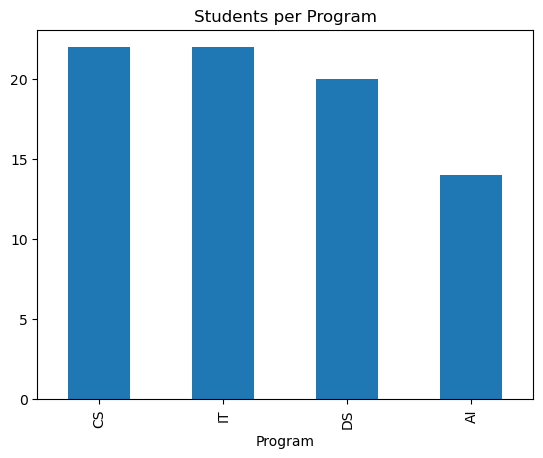

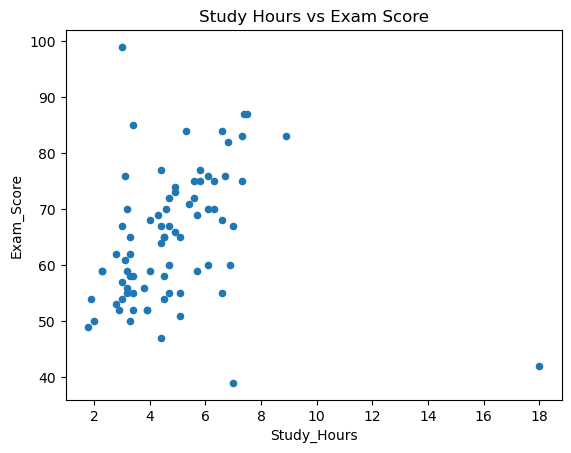

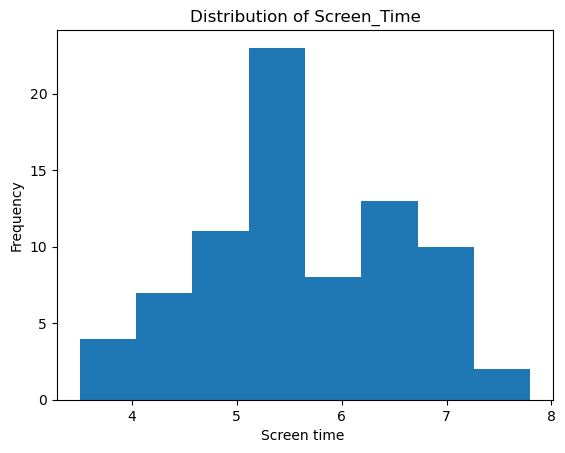

count    78.000000
mean      5.611538
std       0.953732
min       3.500000
25%       5.025000
50%       5.600000
75%       6.300000
max       7.800000
Name: Screen_Time, dtype: float64


In [ ]:
# === Write your answer here: ===
#1-
rem_cle['Program'].value_counts().plot(kind='bar', title='Students per program')
plt.show()

#2-
rem_cle.plot(kind='scatter', x='Study_Hours', y='Exam_Score', title='Study hours vs Exam score')
plt.show()

#3-
rem_cle['Screen_Time'].plot(kind='hist', bins=8, title='Distribution of screen time')
plt.xlabel('Screen time ')
plt.show()
print(rem_cle['Screen_Time'].describe())

#4-
#S173 studies 18 hours a day but scored only 42 so it appears far to the right of the other points in the scatter plot



#5-
rem_cle.to_csv('student_learning_prepared.csv', index=False)



## Final reflection (write 3–5 sentences)

1. Which two preprocessing decisions mattered most for reliable analysis?
2. How did Week 3 visualization help you detect or understand a problem?
3. What did the Week 2 random sample show you about variation between a sample and the full dataset?

**Reminder:** Good data analysis requires both correct Python operations and defensible decisions.

**Reflection answers**

1. The two most important decisions were standardizing the Program labels and correcting only the verified error (S140) while keeping the unverified value (S173).
2. The bar chart showed too many bars for only four programs, and the box plot showed extreme study-hours values, which helped me find the problems.
3. The random sample mean was close to the full dataset mean but not equal, which shows that a sample varies from the full data.